# Visualiszing CBX dynamics

In [66]:
%load_ext autoreload
%autoreload 2
import numpy as np
import cbx as cbx
from cbx.dynamics import CBO, QCBO
from cbx.objectives import Rastrigin
from cbx.utils.objective_handling import cbx_objective_fh
from cbx.scheduler import effective_sample_size
from cbx.plotting import plot_dynamic, plot_dynamic_history

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [67]:
from cbx.utils.history import track
from cbx.dynamics import ParticleDynamic

class track_avg_energy(track):
    """
    Class for tracking of variable 'x' in the history dictionary.
    """
    @staticmethod
    def init_history(dyn: ParticleDynamic):
        dyn.history['avg_energy'] = []
    
    @staticmethod
    def update(dyn) -> None:
        """
        Update the history of the 'x' variable by copying the current particles to the next time step.

        Parameters
        ----------
            dyn : object
                The object to track in the history dictionary.

        Returns
        -------
            None
        """
        dyn.history['avg_energy'].append(np.mean(dyn.energy))

In [98]:
np.random.seed(420)

N = 10000

conf = {'alpha': 10.0**15,
        'dt': 0.02,
        'sigma': 2.,
        'lamda': 1.,
        'batch_args':{
        'batch_size':200,
        'batch_partial': False},
        'd': 2,
        'max_it': 250,
        'N': N,
        'M': 1,
        'track_args': {'names':
                       ['update_norm', 
                        'energy','x', 
                        'consensus', 
                        'drift'],
                       "extra_tracks": [track_avg_energy]},
       }

## Using the plotting functions

....................
Starting Optimization with dynamic: CBO
....................
Time: 0.010, best current energy: [0.11556081]
Number of function evaluations: [20000]
Time: 0.020, best current energy: [0.10564587]
Number of function evaluations: [30000]
Time: 0.030, best current energy: [0.07906987]
Number of function evaluations: [40000]
Time: 0.040, best current energy: [0.07906987]
Number of function evaluations: [50000]
Time: 0.050, best current energy: [0.07906987]
Number of function evaluations: [60000]
Time: 0.060, best current energy: [0.07403382]
Number of function evaluations: [70000]
Time: 0.070, best current energy: [0.07403382]
Number of function evaluations: [80000]
Time: 0.080, best current energy: [0.07403382]
Number of function evaluations: [90000]
Time: 0.090, best current energy: [0.07171891]
Number of function evaluations: [100000]
Time: 0.100, best current energy: [0.0310782]
Number of function evaluations: [110000]
Time: 0.110, best current energy: [0.0310782]
N

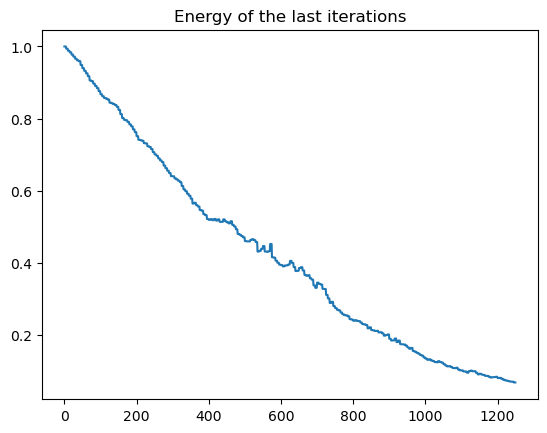

In [75]:
f = Rastrigin()
x = cbx.utils.init_particles(shape=(conf['M'], conf['N'], conf['d']), x_min=-2.5, x_max = 5.) # Define the initial positions of the particles
sched = effective_sample_size(maximum=1e12)
dyn = CBO(f, x=x, noise='anisotropic', f_dim='3D', **conf) # Define the CBO algorithm
dyn.optimize(None, sched)

import matplotlib.pyplot as plt
max_iter = min(int(2.5 / conf['dt']), conf['max_it'])
norms = np.linalg.norm(dyn.history['x'][1:], axis=-1)
results = np.mean(norms, -1)/(2*conf["N"])
plt.plot(results/results[1])
plt.title('Energy of the last iterations')
plt.show()

In [101]:
from IPython import display
qconf = conf.copy()

# for sigma in [0.1, 0.5, 1.0, 2.0, 2.5, 3.0, 4.0, 5.0]:
#     for lamda in [0.1, 0.5, 1.0, 2.0, 2.5, 3.0, 4.0, 5.0]:

qconf["sigma"] = 2.9
qconf["lamda"] = 18
qdyn = QCBO(f, x=x, **qconf)
qdyn.optimize(None, sched)
# fig, ax = plt.subplots(1,2, figsize=(15,5))
# plotter = plot_dynamic(dyn, ax=ax[0],
#                        objective_args={'x_min':-3, 'x_max':3},
#                        plot_consensus=True,
#                        plot_drift=True)
# plotter.init_plot()

# print(qdyn.it)
# import inspect
# print(inspect.getsource(qdyn.inner_step))

# while not qdyn.terminate():
#     qdyn.step()
#     sched.update(dyn)
#     # update energy plot
#     ax[1].clear()
#     ax[1].plot([e[0] for e in qdyn.history['energy'][-30:]])
#     ax[1].set_title('Energy of the last 30 iterations') 
#     ax[0].set_title('Iteration: ' + str(qdyn.it)) 
#     plotter.update(wait=0.2)
#     display.display(fig)
#     display.clear_output(wait=True)
# print(qdyn.terminate())

....................
Starting Optimization with dynamic: QCBO
....................
Time: 0.020, best current energy: [0.11556081]
Number of function evaluations: [20000]
Time: 0.040, best current energy: [0.11556081]
Number of function evaluations: [30000]
Time: 0.060, best current energy: [0.02320927]
Number of function evaluations: [40000]
Time: 0.080, best current energy: [0.02320927]
Number of function evaluations: [50000]
Time: 0.100, best current energy: [0.02320927]
Number of function evaluations: [60000]
Time: 0.120, best current energy: [0.02320927]
Number of function evaluations: [70000]
Time: 0.140, best current energy: [0.02320927]
Number of function evaluations: [80000]
Time: 0.160, best current energy: [0.02320927]
Number of function evaluations: [90000]
Time: 0.180, best current energy: [0.02320927]
Number of function evaluations: [100000]
Time: 0.200, best current energy: [0.02320927]
Number of function evaluations: [110000]
Time: 0.220, best current energy: [0.02320927

array([[-8.85564881e-07, -3.75018525e-07]])

In [117]:

norms = np.linalg.norm(qdyn.history['x'][1:], axis=-1)
print(np.argmin(norms[-1][0]))

6009


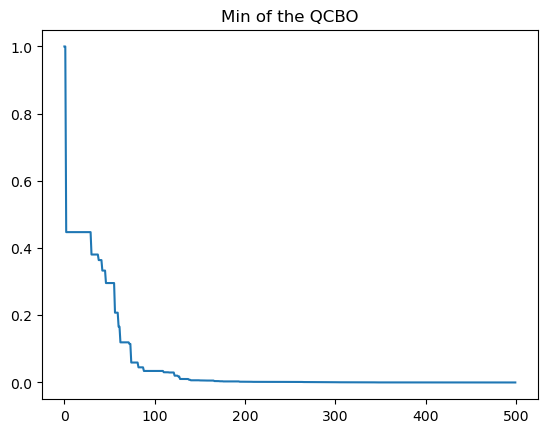

In [121]:
import matplotlib.pyplot as plt
max_iter = min(int(2.5 / conf['dt']), conf['max_it'])
norms = np.linalg.norm(qdyn.history['x'][1:], axis=-1)
mean_results = np.mean(norms, -1)/(2*conf["N"])
# plt.plot(mean_results/mean_results[1])
plt.plot(np.min(norms, -1)/np.min(norms, -1)[1])
plt.title('Min of the QCBO')
plt.show()

In [60]:
import numpy as np
from math import log10

# Save a list
l = [e[0] for e in dyn.history['x']]
np.save(f'x_history_d{conf["d"]}_N{conf["N"]}_M{conf["M"]}_dt{str(conf["dt"]).replace(".", "")}_alpha_10_{int(log10(conf["alpha"]))}.npy', l)

In [41]:
a = np.array([[1,2,3,4], [5,6,7,8]])
b = np.array([5,6,7,8])

np.linalg.norm(a, axis=-1)

array([ 5.47722558, 13.19090596])

In [ ]:
print(len(dyn.history['x'][0][0][0]))
for it in range(len(dyn.history['x'])):
    for m in range(conf['M']):
        for n in range(conf['N']):
            print(np.linalg.norm(dyn.history['x'][it][m][n]))


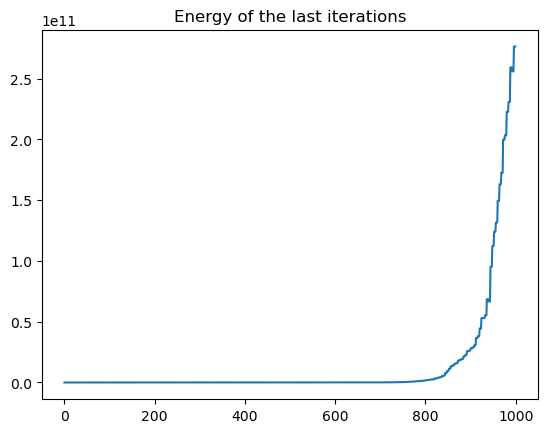

In [74]:
import matplotlib.pyplot as plt
max_iter = min(int(2.5 / conf['dt']), conf['max_it'])
norms = np.linalg.norm(dyn.history['x'][1:], axis=-1)
results = np.mean(norms, -1)/(2*conf["N"])
plt.plot(results/results[1])
plt.title('Energy of the last iterations')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
plt.close('all')
plotter = plot_dynamic_history(
            dyn, dims=[0,1], 
            objective_args={'x_min':-3, 'x_max':3, 'cmap':'viridis',
                            'num_pts':300},
            particle_args = {'s':50, 'c':'xkcd:sky', 'marker':'o'},
            drift_args = {'color':'pink', 'width':0.003},
            plot_consensus=True,
            plot_drift=True)
plotter.run_plots(wait=0.5, freq=1,)